In [1]:
# === Ô GHI LOG (mẫu PL1 bản 2 – chạy được với ipykernel 7): mọi thứ in ra màn hình đồng thời được ghi vào file log ===
import logging, sys, datetime, warnings
from pathlib import Path
TEN_NOTEBOOK = "02_E0.5_rq1_theo_gio_va_thu_Han"
NGUOI_CHAY   = "Han"

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # thư mục gốc repo
thu_muc_log = ROOT / "logs" / "eda_log"
thu_muc_log.mkdir(parents=True, exist_ok=True)
file_log = thu_muc_log / f"{datetime.datetime.now():%Y-%m-%d_%H%M}_{TEN_NOTEBOOK}.log"
tep_log = open(file_log, "a", encoding="utf-8", buffering=1)

if hasattr(sys.stdout, "echo"):                  # chạy trong Jupyter / VS Code: nhờ kernel chép thêm ra file, không thay sys.stdout
    sys.stdout.echo = tep_log
    sys.stderr.echo = tep_log
else:                                            # chạy bằng python thường
    class GhiCaHai:
        def __init__(self, man_hinh, tep): self.man_hinh, self.tep = man_hinh, tep
        def write(self, s): self.man_hinh.write(s); self.tep.write(s); return len(s)
        def flush(self): self.man_hinh.flush(); self.tep.flush()
        def __getattr__(self, ten): return getattr(self.man_hinh, ten)
    sys.stdout = GhiCaHai(sys.__stdout__, tep_log)

logging.basicConfig(stream=sys.stdout, level=logging.INFO, force=True,
                    format="%(asctime)s | %(levelname)s | %(message)s", datefmt="%Y-%m-%d %H:%M:%S")
logging.captureWarnings(True)
log = logging.getLogger(TEN_NOTEBOOK)
log.info(f"Bắt đầu chạy {TEN_NOTEBOOK} – người chạy: {NGUOI_CHAY} – file log: {file_log}")

2026-11-14 00:01:23 | INFO | Bắt đầu chạy 02_E0.5_rq1_theo_gio_va_thu_Han – người chạy: Han – file log: /Users/caongochan/Documents/Nhom11_DuBaoDienNang_GiuaKy/logs/eda_log/2026-11-14_0001_02_E0.5_rq1_theo_gio_va_thu_Han.log


# E0.5 – RQ1: theo giờ trong ngày và thứ trong tuần

| | |
|---|---|
| **Tác giả** | Cao Ngọc Hân – Nhóm 11 |
| **Ngày tạo** | 13/11/2026 |
| **Thí nghiệm** | E0.5 – RQ1: theo giờ trong ngày và thứ trong tuần |
| **Mục đích** | Tách từ `02_eda.ipynb`: RQ1 (a), (b) (mục 3, 4). |
| **Đọc vào** | `data/processed/hourly_clean.csv` (do `01_cleaning` tạo) |
| **Ghi ra** | `data/eda_data/eda_rq1_theo_gio.csv`, `data/eda_data/eda_rq1_theo_thu.csv`, `figures/eda_figures/02_rq1_theo_gio.*`, `figures/eda_figures/02_rq1_theo_thu_heatmap.*` |
| **Chạy sau** | `01_cleaning.ipynb` (cần `hourly_clean.csv`) |

Notebook EDA chỉ đọc và mô tả dữ liệu, không sửa, không xoá, không điền dữ liệu. Bản gộp đọc từ trên xuống: `00_EDA_tong_hop_Han.ipynb`.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # notebook nằm ở notebooks/eda_notebooks/
FILE = ROOT / "data" / "processed" / "hourly_clean.csv"
DIR_DATA = ROOT / "data" / "eda_data"
DIR_FIG = ROOT / "figures" / "eda_figures"
DIR_FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "svg.fonttype": "none"})

MEAN_COLS = ["Global_active_power", "Global_reactive_power", "Voltage", "Global_intensity"]
SUB_COLS = ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]
COLS = MEAN_COLS + SUB_COLS
TARGET = "Global_active_power"
VAR_RQ2 = ["Voltage", "Global_intensity", "Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]

DOW_LABEL = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]
SEASON_ORDER = ["Xuân", "Hè", "Thu", "Đông"]
PERIOD_LABEL = {1: "Năm 1\n12/2006–11/2007", 2: "Năm 2\n12/2007–11/2008",
                3: "Năm 3\n12/2008–11/2009", 4: "Năm 4\n12/2009–11/2010"}

def season_of(m):
    """Mùa theo khí hậu Pháp (bắc bán cầu): Đông 12-2, Xuân 3-5, Hè 6-8, Thu 9-11."""
    if m in (12, 1, 2): return "Đông"
    if m in (3, 4, 5): return "Xuân"
    if m in (6, 7, 8): return "Hè"
    return "Thu"

def vn(x, d=3):
    """Số kiểu Việt Nam: dấu phẩy thập phân."""
    return f"{x:.{d}f}".replace(".", ",")

def fmt(n):
    return f"{int(n):,}".replace(",", ".")

def strength(r):
    a = abs(r)
    if a >= 0.7: return "mạnh"
    if a >= 0.4: return "trung bình"
    if a >= 0.2: return "yếu"
    return "rất yếu"

def save_fig(name):
    plt.savefig(DIR_FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.savefig(DIR_FIG / f"{name}.svg", bbox_inches="tight")

notes = []   # các câu gợi ý nhận xét (số liệu tự điền)
def add_note(tag, text):
    notes.append(f"- **[{tag}]** {text}")

In [3]:
raw = pd.read_csv(FILE, parse_dates=["datetime"], index_col="datetime")
assert (raw.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all(), "Trục giờ không liên tục"

df = raw[COLS].copy()                       # chỉ 7 cột gốc, không dùng *_ffill
df["hour"] = df.index.hour
df["dow"] = df.index.dayofweek              # 0 = thứ 2 ... 6 = chủ nhật
df["is_weekend"] = df["dow"] >= 5
df["month"] = df.index.month
df["season"] = df["month"].map(season_of)
# Năm vận hành: tháng 12 đến tháng 11 năm sau (khớp với khoảng dữ liệu 12/2006 đến 11/2010)
df["period"] = np.asarray(((df.index.year * 12 + df.index.month) - (2006 * 12 + 12)) // 12 + 1)

n_all = len(df)
n_valid = int(df[TARGET].notna().sum())
print(f"Tổng số giờ: {fmt(n_all)} | Giờ có số đo thật: {fmt(n_valid)} | Giờ thiếu (bỏ qua): {fmt(n_all - n_valid)}")
print("Khoảng thời gian:", df.index[0], "->", df.index[-1])
print("Số giờ có số đo theo mùa:\n", df.groupby("season")[TARGET].count().reindex(SEASON_ORDER))
df.head()

Tổng số giờ: 34.588 | Giờ có số đo thật: 34.157 | Giờ thiếu (bỏ qua): 431
Khoảng thời gian: 2006-12-16 17:00:00 -> 2010-11-26 20:00:00
Số giờ có số đo theo mùa:
 season
Xuân    8736
Hè      8639
Thu     8549
Đông    8233
Name: Global_active_power, dtype: int64


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,hour,dow,is_weekend,month,season,period
datetime,,,,,,,,,,,,,
2006-12-16 17:00:00,4.2229,0.2290,234.6439,18.1000,0.0,31.6667,1011.6667,17,5,True,12,Đông,1
2006-12-16 18:00:00,3.6322,0.0800,234.5802,15.6000,0.0,403.0000,1012.0000,18,5,True,12,Đông,1
2006-12-16 19:00:00,3.4002,0.0852,233.2325,14.5033,0.0,86.0000,1001.0000,19,5,True,12,Đông,1
2006-12-16 20:00:00,3.2686,0.0751,234.0715,13.9167,0.0,0.0000,1007.0000,20,5,True,12,Đông,1
2006-12-16 21:00:00,3.0565,0.0767,237.1587,13.0467,0.0,25.0000,1033.0000,21,5,True,12,Đông,1


In [4]:
MA_TN = "E0.5"
moc_note = len(notes)    # các câu gợi ý nhận xét từ đây trở đi thuộc E0.5

## 3. RQ1 (a): Theo giờ trong ngày, ngày thường và cuối tuần
- Hình trái: công suất trung bình theo từng giờ trong ngày, dải màu là khoảng từ phân vị 25% đến 75%.
- Hình phải: so sánh ngày thường (T2 đến T6) và cuối tuần (T7, CN).

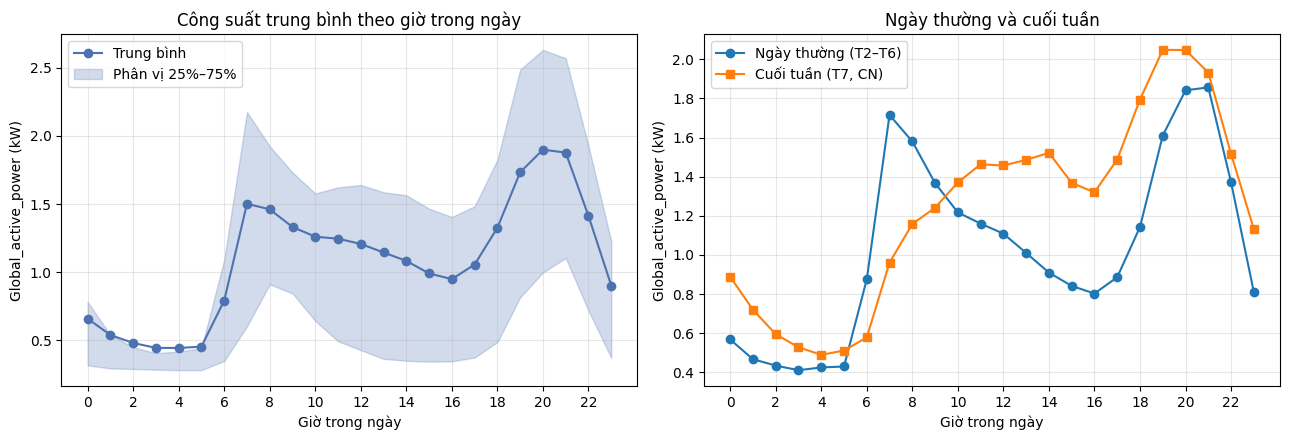

,tat_ca,q25,q75,do_lech_chuan,so_gio_do,ngay_thuong,cuoi_tuan
hour,,,,,,,
0,0.659,0.317,0.782,0.618,1425,0.569,0.888
1,0.539,0.294,0.539,0.501,1424,0.468,0.721
2,0.481,0.290,0.450,0.410,1424,0.435,0.596
3,0.445,0.285,0.406,0.357,1424,0.412,0.529
4,0.444,0.281,0.417,0.344,1422,0.426,0.490
5,0.454,0.282,0.443,0.354,1421,0.431,0.512
6,0.792,0.348,1.092,0.513,1421,0.875,0.579
7,1.502,0.602,2.175,0.894,1421,1.715,0.961
8,1.461,0.911,1.924,0.753,1422,1.580,1.158


In [5]:
g = df.groupby("hour")[TARGET]
prof = pd.DataFrame({"tat_ca": g.mean(), "q25": g.quantile(0.25), "q75": g.quantile(0.75),
                     "do_lech_chuan": g.std(), "so_gio_do": g.count()})
wk = (df.groupby(["hour", "is_weekend"])[TARGET].mean().unstack()
        .rename(columns={False: "ngay_thuong", True: "cuoi_tuan"}))
prof = prof.join(wk)
prof.round(4).to_csv(DIR_DATA / "eda_rq1_theo_gio.csv", index_label="gio")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(prof.index, prof["tat_ca"], marker="o", color="#4C72B0", label="Trung bình")
ax[0].fill_between(prof.index, prof["q25"], prof["q75"], alpha=0.25, color="#4C72B0", label="Phân vị 25%–75%")
ax[0].set_title("Công suất trung bình theo giờ trong ngày")
ax[0].set_xlabel("Giờ trong ngày"); ax[0].set_ylabel("Global_active_power (kW)")
ax[0].set_xticks(range(0, 24, 2)); ax[0].legend()
ax[1].plot(prof.index, prof["ngay_thuong"], marker="o", label="Ngày thường (T2–T6)")
ax[1].plot(prof.index, prof["cuoi_tuan"], marker="s", label="Cuối tuần (T7, CN)")
ax[1].set_title("Ngày thường và cuối tuần")
ax[1].set_xlabel("Giờ trong ngày"); ax[1].set_ylabel("Global_active_power (kW)")
ax[1].set_xticks(range(0, 24, 2)); ax[1].legend()
plt.tight_layout()
save_fig("02_rq1_theo_gio")
plt.show()
prof.round(3)

In [6]:
pk_h, tr_h = int(prof["tat_ca"].idxmax()), int(prof["tat_ca"].idxmin())
mor_h = int(prof.loc[5:12, "tat_ca"].idxmax())     # đỉnh trong khung 5h-12h
eve_h = int(prof.loc[17:23, "tat_ca"].idxmax())    # đỉnh trong khung 17h-23h
add_note("RQ1-giờ", f"Công suất trung bình cao nhất lúc {pk_h}h ({vn(prof.loc[pk_h, 'tat_ca'])} kW) và thấp nhất lúc {tr_h}h "
         f"({vn(prof.loc[tr_h, 'tat_ca'])} kW), gấp {vn(prof.loc[pk_h, 'tat_ca'] / prof.loc[tr_h, 'tat_ca'], 1)} lần. "
         f"Đỉnh trong khung 5h–12h là lúc {mor_h}h ({vn(prof.loc[mor_h, 'tat_ca'])} kW); đỉnh trong khung 17h–23h là lúc {eve_h}h ({vn(prof.loc[eve_h, 'tat_ca'])} kW).")

wd_mean = df.loc[~df["is_weekend"], TARGET].mean()
we_mean = df.loc[df["is_weekend"], TARGET].mean()
diff_pct = (we_mean / wd_mean - 1) * 100
add_note("RQ1-cuối tuần", f"Trung bình cả ngày: ngày thường {vn(wd_mean)} kW, cuối tuần {vn(we_mean)} kW; cuối tuần "
         f"{'cao hơn' if diff_pct > 0 else 'thấp hơn'} ngày thường {vn(abs(diff_pct), 1)}%.")
dh = prof["cuoi_tuan"] - prof["ngay_thuong"]
h_max = int(dh.abs().idxmax())
add_note("RQ1-cuối tuần", f"Chênh lệch giữa cuối tuần và ngày thường lớn nhất lúc {h_max}h: cuối tuần "
         f"{'cao hơn' if dh[h_max] > 0 else 'thấp hơn'} {vn(abs(dh[h_max]))} kW "
         f"({vn(prof.loc[h_max, 'cuoi_tuan'])} so với {vn(prof.loc[h_max, 'ngay_thuong'])} kW).")

**Nhận xét:** Công suất cao nhất lúc 20h (1,899 kW), thấp nhất lúc 4h (0,444 kW), gấp 4,3 lần; có hai đỉnh trong ngày là 7h (1,502 kW) và 20h. Cuối tuần trung bình 1,234 kW, cao hơn ngày thường (1,035 kW) 19,2%; chênh lệch rõ nhất lúc 7h (ngày thường 1,715 kW, cuối tuần 0,961 kW) vì sáng cuối tuần không có giờ cao điểm đi làm, đi học. Giờ trong ngày là yếu tố ảnh hưởng rõ nhất nên cần đưa đặc trưng giờ vào mô hình.

## 4. RQ1 (b): Theo thứ trong tuần và bản đồ nhiệt giờ × thứ

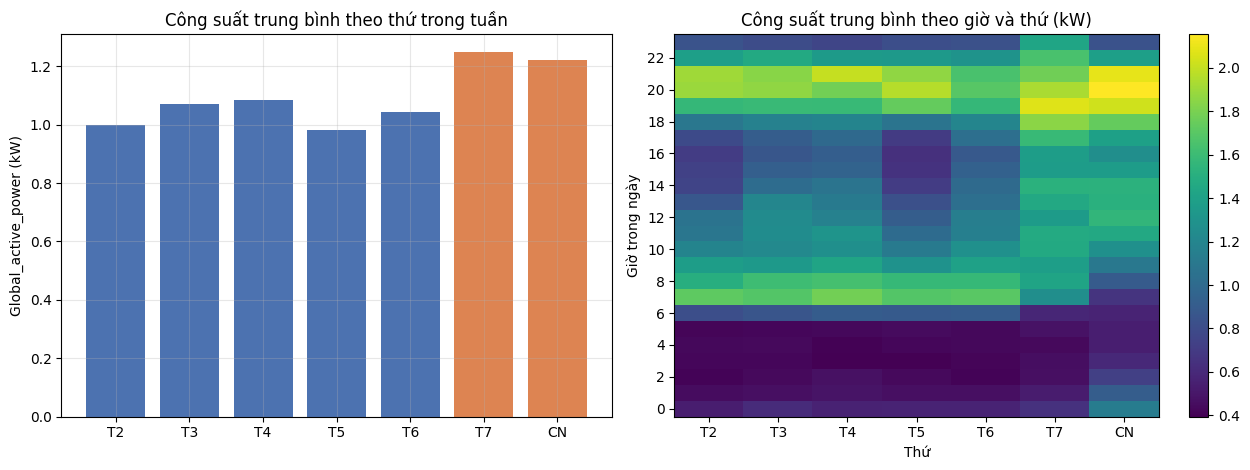

,mean,std,count
T2,0.999,0.812,4898
T3,1.070,0.861,4913
T4,1.083,0.855,4895
T5,0.982,0.824,4886
T6,1.043,0.820,4917
T7,1.248,1.022,4814
CN,1.220,1.029,4834


In [7]:
d = df.groupby("dow")[TARGET].agg(["mean", "std", "count"])
d.index = DOW_LABEL
d.round(4).to_csv(DIR_DATA / "eda_rq1_theo_thu.csv", index_label="thu")

pv = df.pivot_table(index="hour", columns="dow", values=TARGET, aggfunc="mean")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.1]})
colors = ["#4C72B0"] * 5 + ["#DD8452"] * 2
ax[0].bar(d.index, d["mean"], color=colors)
ax[0].set_title("Công suất trung bình theo thứ trong tuần")
ax[0].set_ylabel("Global_active_power (kW)")
im = ax[1].imshow(pv.values, aspect="auto", origin="lower", cmap="viridis")
ax[1].set_xticks(range(7)); ax[1].set_xticklabels(DOW_LABEL)
ax[1].set_yticks(range(0, 24, 2)); ax[1].set_yticklabels(range(0, 24, 2))
ax[1].set_title("Công suất trung bình theo giờ và thứ (kW)")
ax[1].set_xlabel("Thứ"); ax[1].set_ylabel("Giờ trong ngày"); ax[1].grid(False)
plt.colorbar(im, ax=ax[1])
plt.tight_layout()
save_fig("02_rq1_theo_thu_heatmap")
plt.show()
d.round(3)

In [8]:
best_d, worst_d = d["mean"].idxmax(), d["mean"].idxmin()
add_note("RQ1-thứ", f"Thứ có công suất trung bình cao nhất là {best_d} ({vn(d.loc[best_d, 'mean'])} kW), thấp nhất là {worst_d} ({vn(d.loc[worst_d, 'mean'])} kW); "
         f"chênh nhau {vn((d.loc[best_d, 'mean'] / d.loc[worst_d, 'mean'] - 1) * 100, 1)}%.")

**Nhận xét:** Thứ Bảy có công suất trung bình cao nhất (1,248 kW), thứ Năm thấp nhất (0,982 kW), chênh nhau 27,2%. Bản đồ nhiệt cho thấy sáng ngày thường có đỉnh rõ lúc 7h, còn cuối tuần tiêu thụ trải đều hơn từ trưa đến chiều. Đây là cơ sở để dùng đặc trưng thứ và cờ cuối tuần.

## Gợi ý nhận xét E0.5 (số tự điền)

In [9]:
goi_y = "\n".join(notes[moc_note:])
(DIR_DATA / f"eda_{MA_TN}_goi_y_nhan_xet.md").write_text(goi_y, encoding="utf-8")
log.info(f"Gợi ý nhận xét {MA_TN} (số tự điền), lưu ở data/eda_data/eda_{MA_TN}_goi_y_nhan_xet.md:\n" + goi_y)

2026-11-14 00:01:24 | INFO | Gợi ý nhận xét E0.5 (số tự điền), lưu ở data/eda_E0.5_goi_y_nhan_xet.md:
- **[RQ1-giờ]** Công suất trung bình cao nhất lúc 20h (1,899 kW) và thấp nhất lúc 4h (0,444 kW), gấp 4,3 lần. Đỉnh trong khung 5h–12h là lúc 7h (1,502 kW); đỉnh trong khung 17h–23h là lúc 20h (1,899 kW).
- **[RQ1-cuối tuần]** Trung bình cả ngày: ngày thường 1,035 kW, cuối tuần 1,234 kW; cuối tuần cao hơn ngày thường 19,2%.
- **[RQ1-cuối tuần]** Chênh lệch giữa cuối tuần và ngày thường lớn nhất lúc 7h: cuối tuần thấp hơn 0,754 kW (0,961 so với 1,715 kW).
- **[RQ1-thứ]** Thứ có công suất trung bình cao nhất là T7 (1,248 kW), thấp nhất là T5 (0,982 kW); chênh nhau 27,2%.


## Log lên W&B (minh chứng)

In [10]:
# W&B (project cuoi-ky-du-bao-dien-nang). Mặc định TẮT để chạy lại không tạo run trùng.
# Muốn ghi lên W&B: chạy notebook bằng lệnh  BAT_WANDB=1 jupyter nbconvert --to notebook --execute --inplace <notebook>
import os
USE_WANDB = os.environ.get("BAT_WANDB") == "1"
if USE_WANDB:
    import wandb, pandas as pd
    BANG = ['eda_rq1_theo_gio.csv', 'eda_rq1_theo_thu.csv']
    HINH = ['02_rq1_theo_gio.png', '02_rq1_theo_thu_heatmap.png']
    run = wandb.init(entity="sgu-mayhoc-nhom11", project="cuoi-ky-du-bao-dien-nang",
                     name="ck-E0.5-Han-rq1-theo-gio-va-thu", tags=["E0.5", "Han", "EDA"],
                     config={"notebook": TEN_NOTEBOOK, "file_log": str(file_log)})
    run.summary.update({})
    run.log({**{"bang/" + b.removesuffix(".csv"): wandb.Table(dataframe=pd.read_csv(DIR_DATA / b)) for b in BANG},
             **{"hinh/" + h.removesuffix(".png"): wandb.Image(str(DIR_FIG / h)) for h in HINH},
             "ket_luan": wandb.Html("<br>".join(str(x) for x in notes[moc_note:]))})
    log.info(f"Đã ghi W&B: {run.url}")
    run.finish()

wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from /Users/caongochan/.netrc.


wandb: Currently logged in as: caongochan142 (sgu-mayhoc-nhom11) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


wandb: setting up run wheq6f2j


wandb: Tracking run with wandb version 0.31.0


wandb: Run data is saved locally in /Users/caongochan/Documents/Nhom11_DuBaoDienNang_GiuaKy/notebooks/eda/wandb/run-20261114_000125-wheq6f2j
wandb: Run `wandb offline` to turn off syncing.


wandb: Syncing run ck-E0.5-Han-rq1-theo-gio-va-thu


... (7 outputs left out)

wandb: uploading artifact run-wheq6f2j-bangeda_rq1_theo_thu-BPnhpA; uploading media/images/hinh/02_rq1_theo_gio_0_0a2489e5917d52860cb3.png


wandb: uploading history steps 0-0, summary, console lines 0-0


wandb: 🚀 View run ck-E0.5-Han-rq1-theo-gio-va-thu at: https://forge.coreweave.com/wandb/sgu-mayhoc-nhom11/cuoi-ky-du-bao-dien-nang/runs/wheq6f2j
wandb: ⭐️ View project at: https://forge.coreweave.com/wandb/sgu-mayhoc-nhom11/cuoi-ky-du-bao-dien-nang
wandb: Synced 5 W&B file(s), 5 media file(s), 4 artifact file(s) and 0 other file(s)


wandb: Find logs at: ./wandb/run-20261114_000125-wheq6f2j/logs


## Nhật ký

- 01/11/2026 – Viết lần đầu trong notebook `02_eda.ipynb`. Commit `74a9949`.
- 07/11/2026 – Sửa `02_eda.ipynb`. Commit `9a1f293`, `910a450`.
- 13/11/2026 – Tách RQ1 (a), (b) (mục 3, 4) ra khỏi `02_eda.ipynb` thành notebook riêng `02_E0.5_rq1_theo_gio_va_thu_Han.ipynb`, thêm ô ghi log. Commit `cdf1bfd` (lúc này notebook chưa chạy).
- 13/11/2026 – Chạy lúc 19:59, commit log và bảng kết quả. Commit `4025336`.
- 13/11/2026 – Lưu notebook có output (commit trước chưa kèm notebook đã chạy). Commit `eff052c`.
- 13/11/2026 – Chuyển các file log EDA vào `logs/eda_log/` và sửa ô ghi log để các lần chạy sau ghi thẳng vào thư mục này. Commit `44b69dd`.